# QMetric: Learning Similarity Geometry in Embedding Spaces via Quantum Kernel Metric Layers

**Research Project** Quantum Machine Learning × Metric Learning  
**Dataset**: [UCI Devanagari Handwritten Character Dataset](https://archive.ics.uci.edu/dataset/389/devanagari+handwritten+character+dataset)  
(46 classes, 78,200 / 13,800 train-test)
### Core Claims to` Validate (based on preliminary research paper draft)

* **C1:** QML is modular. It can be plugged into any encoder
* **C2:** Quantum RKHS strictly contains polynomial RKHS, implying higher expressivity
* **C3:** GAL loss prevents quantum kernel collapse
* **C4:** Demonstrates better sample efficiency in low-data regimes
* **C5:** Achieves good % mean improvement in disambiguation on hardest confusion pairs

### Notebook Structure
1. Setup & Configuration  
2. Dataset Loading, EDA & Visualization  
3. Conv-4 Encoder Training & Embedding Extraction  
4. Classical Metric Learning (All Baselines)  
5. Quantum Metric Layer (QML + GAL Loss)  
6. Protocol A: Classification at 10%, 20%, 50%, 100% Data  
7. Protocol B: 5-way K-shot Few-Shot Episodic Evaluation
8. Protocol C: Confusion-Pair Stress Test (10 Hardest Pairs)
9. Ablation Study (C3 validation)  
10. Statistical Analysis & Significance Testing
11. Comprehensive Analysis & Visualization  
12. Benchmarking Report & Conclusion
13. Conclusion

## Section 1: Setup

In [ ]:
PACKAGES = [
    "pennylane", "pennylane-lightning", "metric-learn",
    "torch", "torchvision", "matplotlib", "seaborn",
    "tqdm", "scipy", "pandas", "scikit-learn",
]

for pkg in PACKAGES:
    print(f"Installing {pkg}")
    !pip install {pkg}

In [23]:
######################################
# Importing Necessary Packages
######################################
import os, sys, random, warnings, time
from pathlib import Path
from copy import deepcopy
from itertools import combinations
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import ttest_rel, wilcoxon
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset, Subset, WeightedRandomSampler
from torchvision import datasets, transforms

import pennylane as qml
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, f1_score, confusion_matrix,
                              classification_report)
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.model_selection import StratifiedShuffleSplit
import inspect
import sklearn.utils.validation as sk_validation

if "force_all_finite" not in inspect.signature(sk_validation.check_X_y).parameters:
    _orig_check_X_y = sk_validation.check_X_y
    _orig_check_array = sk_validation.check_array

    def _check_X_y_compat(*args, force_all_finite=None, ensure_all_finite=None, **kwargs):
        if ensure_all_finite is None and force_all_finite is not None:
            ensure_all_finite = force_all_finite
        if ensure_all_finite is not None:
            kwargs["ensure_all_finite"] = ensure_all_finite
        return _orig_check_X_y(*args, **kwargs)

    def _check_array_compat(*args, force_all_finite=None, ensure_all_finite=None, **kwargs):
        if ensure_all_finite is None and force_all_finite is not None:
            ensure_all_finite = force_all_finite
        if ensure_all_finite is not None:
            kwargs["ensure_all_finite"] = ensure_all_finite
        return _orig_check_array(*args, **kwargs)

    sk_validation.check_X_y = _check_X_y_compat
    sk_validation.check_array = _check_array_compat

    try:
        import metric_learn._util as ml_util
        ml_util.check_X_y = _check_X_y_compat
        ml_util.check_array = _check_array_compat
    except Exception:
        pass

from metric_learn import LMNN

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="muted")

SEED = 42
def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
set_seed()

# pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu118 
# do above if gpu 
print(torch.__version__)
print(torch.version.cuda)
print(torch.cuda.is_available())
if torch.cuda.is_available():
    print("NVIDIA GPU detected!")
    print("GPU Name:", torch.cuda.get_device_name(0))
    print("CUDA Version:", torch.version.cuda)
else:
    print("No CUDA-compatible NVIDIA GPU found.")
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {DEVICE} | PyTorch: {torch.__version__} | PennyLane: {qml.__version__}")


2.7.1+cu118
11.8
True
NVIDIA GPU detected!
GPU Name: NVIDIA GeForce RTX 3050 Laptop GPU
CUDA Version: 11.8
Device: cuda | PyTorch: 2.7.1+cu118 | PennyLane: 0.45.0


## Section 2: Dataset Loading & Exploratory Data Analysis

In [ ]:
##################################################
# Local dataset check / optional unzip
##################################################

from pathlib import Path

WORKSPACE_ROOT = Path("C:\\Users\\asus\\Downloads\\devanagari+handwritten+character+dataset")
DATA_ROOT = WORKSPACE_ROOT / "DevanagariHandwrittenCharacterDataset"
ZIP_PATH = WORKSPACE_ROOT / "devanagari+handwritten+character+dataset.zip"

if DATA_ROOT.exists():
    print(f"Dataset already available at: {DATA_ROOT}")
elif ZIP_PATH.exists():
    import zipfile
    with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
        zip_ref.extractall(DATA_ROOT.parent)
    print(f"Dataset extracted to: {DATA_ROOT.parent}")
else:
    raise FileNotFoundError(
        f"Could not find dataset at {DATA_ROOT} or archive at {ZIP_PATH}"
    )


Dataset already available at: C:\Users\asus\Downloads\devanagari+handwritten+character+dataset\DevanagariHandwrittenCharacterDataset


In [ ]:
######################################
# Image Transformation Variables
######################################

IMG_SIZE = 32

train_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5], std=[0.5]),
])

val_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5], std=[0.5]),
])

test_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5], std=[0.5]),
])

In [ ]:
##################################################
# Data Load  +  Stratified Validation Split
##################################################

ENCODER_BATCH  = 128

# Use WORKSPACE_ROOT defined earlier
DATA_ROOT = WORKSPACE_ROOT / "DevanagariHandwrittenCharacterDataset"
train_root = DATA_ROOT / "Train"
test_root  = DATA_ROOT / "Test"

VAL_FRAC = 0.10   # 10% of train data → validation set

if train_root.exists():
    full_train_ds = datasets.ImageFolder(str(train_root), transform=train_transform)
    full_test_ds  = datasets.ImageFolder(str(test_root),  transform=test_transform)
    CLASS_NAMES   = full_train_ds.classes
    NUM_CLASSES   = len(CLASS_NAMES)

    # Stratified Validation Split
    all_labels  = np.array(full_train_ds.targets)
    val_indices, train_indices = [], []
    rng_split = np.random.default_rng(SEED)
    for cls in np.unique(all_labels):
        cls_idx = np.where(all_labels == cls)[0]
        n_val   = max(1, int(len(cls_idx) * VAL_FRAC))
        chosen  = rng_split.choice(cls_idx, size=n_val, replace=False)
        val_indices.extend(chosen.tolist())
        chosen_set = set(chosen.tolist())
        train_indices.extend([i for i in cls_idx if i not in chosen_set])

    # Subsets for encoder training
    train_subset_ds = Subset(full_train_ds, train_indices)
    val_subset_ds   = Subset(
        datasets.ImageFolder(str(train_root), transform=val_transform),
        val_indices
    )

    # DataLoaders
    train_loader = DataLoader(train_subset_ds, batch_size=ENCODER_BATCH,
                              shuffle=True, num_workers=0)
    val_loader   = DataLoader(val_subset_ds,   batch_size=ENCODER_BATCH,
                              shuffle=False, num_workers=0)
    test_loader  = DataLoader(full_test_ds,    batch_size=256,
                              shuffle=False, num_workers=0)

    print(f"Dataset loaded")
    print(f"  Full train : {len(full_train_ds)}")
    print(f"  Train split: {len(train_indices)}")
    print(f"  Val split  : {len(val_indices)}")
    print(f"  Test       : {len(full_test_ds)}")
    print(f"  Classes    : {NUM_CLASSES}")
    img, label = full_train_ds[0]
    print(f"  Image shape: {img.shape}")
else:
    print(f"Train path not found: {train_root}")
    full_train_ds = train_subset_ds = val_subset_ds = full_test_ds = None
    train_loader = val_loader = test_loader = None


Dataset loaded
  Full train : 78200
  Train split: 70380
  Val split  : 7820
  Test       : 13800
  Classes    : 46
  Image shape: torch.Size([1, 32, 32])


In [ ]:
##################################################
# Utility for Fractional Dataset Loader
##################################################

def get_fraction_subset(dataset, fraction=1.0, seed=SEED):
    """Return a class-balanced subset of dataset with fraction of each class"""
    random_np_generator  = np.random.default_rng(seed)
    labels = np.array([label for _, label in dataset.samples])
    selected = []
    for cls in np.unique(labels):
        cls_id = np.where(labels == cls)[0]
        n_keep = max(1, int(len(cls_id) * fraction))
        chosen = random_np_generator.choice(cls_id, size=n_keep, replace=False)
        selected.extend(chosen.tolist())
    return Subset(dataset, selected)

def get_labels(dataset):
    """Extract all labels from a dataset or Subset."""
    if isinstance(dataset, Subset):
        return np.array([dataset.dataset.targets[i] for i in dataset.indices])
    return np.array(dataset.targets)

print("Dataset utilities defined")

Dataset utilities defined


Total images in Train directory: 78200
Total images in Test directory: 13800
Choosing Train dataset
Selected class: character_18_da
Image size: (32, 32)


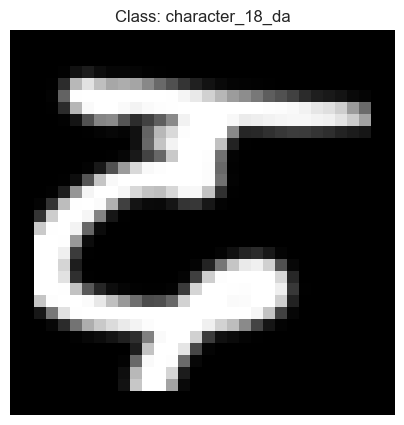

In [ ]:
############################
# Dataset Exploration
############################

from PIL import Image

# Use WORKSPACE_ROOT defined earlier
dataset_path = WORKSPACE_ROOT / "DevanagariHandwrittenCharacterDataset"

train_dir = dataset_path / "Train"
test_dir = dataset_path / "Test"

train_img_files = list(train_dir.rglob("*.png"))
test_img_files = list(test_dir.rglob("*.png"))

print(f"Total images in {train_dir.name} directory: {len(train_img_files)}")
print(f"Total images in {test_dir.name} directory: {len(test_img_files)}")

print(f"Choosing {train_dir.name} dataset")

img_path = random.choice(train_img_files)

class_name = img_path.parent.name
img = Image.open(img_path)

print("Selected class:", class_name)
print("Image size:", img.size)

# plot
plt.figure(figsize=(5,5))
plt.imshow(img, cmap="gray")
plt.title(f"Class: {class_name}")
plt.axis("off")
plt.show()


## Section 3: Conv-4 Encoder Training & Embedding Extraction

In [7]:
############################
# Conv-4 Architecture
############################

EMBED_DIM      = 64

class ConvBlock(nn.Module):
    """Conv2d -> BatchNorm2d -> ReLU -> MaxPool2d"""
    def __init__(self, input_channel, output_channel):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(input_channel, output_channel, 3, padding=1, bias=False),
            nn.BatchNorm2d(output_channel),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
        )
    def forward(self, x):
        return self.block(x)

class Conv4Encoder(nn.Module):
    """4-block convolutional encoder producing EMBED_DIM embeddings."""
    def __init__(self, in_channels=1, hidden_dim=64, embed_dim=EMBED_DIM):
        super().__init__()
        self.encoder = nn.Sequential(
            ConvBlock(in_channels, hidden_dim),
            ConvBlock(hidden_dim, hidden_dim),
            ConvBlock(hidden_dim, hidden_dim),
            ConvBlock(hidden_dim, hidden_dim),
        )
        self.fc    = nn.Linear(hidden_dim * 4, embed_dim)
        self.out_dim = embed_dim

    def forward(self, x):
        h = self.encoder(x)
        return self.fc(h.view(h.size(0), -1))

class Conv4Classifier(nn.Module):
    """Conv4Encoder + linear classifier head (for supervised pre-training)."""
    def __init__(self, n_classes, embed_dim=EMBED_DIM):
        super().__init__()
        self.encoder    = Conv4Encoder(embed_dim=embed_dim)
        self.classifier = nn.Linear(embed_dim, n_classes)

    def forward(self, x):
        emb = self.encoder(x)
        return self.classifier(emb), emb

print("Conv-4 architecture defined")

Conv-4 architecture defined


In [8]:
############################
# Encoder Training — with Validation Loop
############################

ENCODER_EPOCHS = 25
ENCODER_LR     = 1e-3

def train_encoder(train_dataset, val_dataset, n_classes,
                  epochs=ENCODER_EPOCHS, batch_size=ENCODER_BATCH,
                  lr=ENCODER_LR, embed_dim=EMBED_DIM,
                  checkpoint_path="encoder_best.pt", verbose=True):
    """
    Train Conv4Classifier with cross-entropy.
    Saves best checkpoint by validation loss.
    Returns the encoder (without classifier head) + training history.
    """
    tr_loader   = DataLoader(train_dataset, batch_size=batch_size, shuffle=True,  num_workers=0)
    val_loader_ = DataLoader(val_dataset,   batch_size=batch_size, shuffle=False, num_workers=0)

    model     = Conv4Classifier(n_classes, embed_dim).to(DEVICE)
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    criterion = nn.CrossEntropyLoss()

    best_val_loss = float("inf")
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

    for epoch in range(1, epochs + 1):
        # Train
        model.train()
        total_loss = correct = total = 0
        for imgs, labels in tr_loader:
            imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
            optimizer.zero_grad()
            logits, _ = model(imgs)
            loss = criterion(logits, labels)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * imgs.size(0)
            correct    += (logits.argmax(1) == labels).sum().item()
            total      += imgs.size(0)
        tr_loss = total_loss / total
        tr_acc  = correct / total
        history["train_loss"].append(tr_loss)
        history["train_acc"].append(tr_acc)

        # Validate
        model.eval()
        v_loss = v_correct = v_total = 0
        with torch.no_grad():
            for imgs, labels in val_loader_:
                imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
                logits, _ = model(imgs)
                loss = criterion(logits, labels)
                v_loss    += loss.item() * imgs.size(0)
                v_correct += (logits.argmax(1) == labels).sum().item()
                v_total   += imgs.size(0)
        val_loss = v_loss / v_total
        val_acc  = v_correct / v_total
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        scheduler.step()

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            torch.save(model.state_dict(), checkpoint_path)

        if verbose:
            print(f"Epoch {epoch:3d}/{epochs} | "
                  f"Train Loss={tr_loss:.4f} Acc={tr_acc:.4f} | "
                  f"Val Loss={val_loss:.4f} Acc={val_acc:.4f}")

    model.load_state_dict(torch.load(checkpoint_path, map_location=DEVICE))
    print(f"Encoder trained | Best val_loss={best_val_loss:.4f}")
    return model.encoder, history

if full_train_ds is not None:
    print("Training Conv-4 encoder (with validation split for best-model selection)...")
    encoder, enc_history = train_encoder(
        train_subset_ds, val_subset_ds, NUM_CLASSES, verbose=True
    )
else:
    print("Error: Dataset not available.")


Training Conv-4 encoder (with validation split for best-model selection)...


Epoch   1/25 | Train Loss=0.4808 Acc=0.8902 | Val Loss=0.1458 Acc=0.9564
Epoch   2/25 | Train Loss=0.0739 Acc=0.9792 | Val Loss=0.0758 Acc=0.9786
Epoch   3/25 | Train Loss=0.0459 Acc=0.9866 | Val Loss=0.0857 Acc=0.9746
Epoch   4/25 | Train Loss=0.0318 Acc=0.9909 | Val Loss=0.0713 Acc=0.9793
Epoch   5/25 | Train Loss=0.0259 Acc=0.9922 | Val Loss=0.0649 Acc=0.9813
Epoch   6/25 | Train Loss=0.0182 Acc=0.9948 | Val Loss=0.0844 Acc=0.9770
Epoch   7/25 | Train Loss=0.0165 Acc=0.9951 | Val Loss=0.0644 Acc=0.9806
Epoch   8/25 | Train Loss=0.0121 Acc=0.9962 | Val Loss=0.0529 Acc=0.9850
Epoch   9/25 | Train Loss=0.0098 Acc=0.9973 | Val Loss=0.0509 Acc=0.9850
Epoch  10/25 | Train Loss=0.0091 Acc=0.9972 | Val Loss=0.0573 Acc=0.9852
Epoch  11/25 | Train Loss=0.0056 Acc=0.9987 | Val Loss=0.0467 Acc=0.9884
Epoch  12/25 | Train Loss=0.0029 Acc=0.9994 | Val Loss=0.0424 Acc=0.9879
Epoch  13/25 | Train Loss=0.0015 Acc=0.9999 | Val Loss=0.0378 Acc=0.9910
Epoch  14/25 | Train Loss=0.0017 Acc=0.9998 | Val L

In [9]:
############################
# Extract Embeddings (Train / Val / Test)
############################

@torch.no_grad()
def extract_embeddings(encoder, dataset, batch_size=256):
    """Run dataset through encoder and return (embeddings, labels)."""
    encoder.eval()
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False, num_workers=0)
    all_embeddings, all_labels = [], []
    for imgs, labels in loader:
        embs = encoder(imgs.to(DEVICE)).cpu().numpy()
        all_embeddings.append(embs)
        all_labels.extend(labels.numpy())
    return np.vstack(all_embeddings), np.array(all_labels)

def l2_norm(X):
    return X / (np.linalg.norm(X, axis=1, keepdims=True) + 1e-8)

if full_train_ds is not None and full_test_ds is not None:
    print("Extracting embeddings from full train, validation, and test sets...")
    # Full train — subsampled internally in Protocol A/B/C
    embeddings_train_full, lbl_train_full = extract_embeddings(encoder, full_train_ds)
    # Validation split — for validation-set reporting
    embeddings_val, lbl_val               = extract_embeddings(encoder, val_subset_ds)
    # Test set
    embeddings_test, lbl_test             = extract_embeddings(encoder, full_test_ds)

    emb_train_norm = l2_norm(embeddings_train_full)
    emb_val_norm   = l2_norm(embeddings_val)
    emb_test_norm  = l2_norm(embeddings_test)

    print(f"Embeddings extracted")
    print(f"  Full train : {embeddings_train_full.shape}")
    print(f"  Validation : {embeddings_val.shape}")
    print(f"  Test       : {embeddings_test.shape}")
else:
    print("Dataset not available — skipping embedding extraction")


Extracting embeddings from full train, validation, and test sets...
Embeddings extracted
  Full train : (78200, 64)
  Validation : (7820, 64)
  Test       : (13800, 64)


## Section 4: Classical Metric Learning Baselines

In [17]:
############################
# Helper Functions
############################

MAX_CL_TRAIN = 2000

def balanced_class_subsample(labels, max_samples, seed=SEED):
    """Return indices for a class-balanced subsample (max_samples total)."""
    rng     = np.random.default_rng(seed)
    classes = np.unique(labels)
    n_per   = max(1, max_samples // len(classes))
    idx     = []
    for c in classes:
        c_idx  = np.where(labels == c)[0]
        chosen = rng.choice(c_idx, size=min(n_per, len(c_idx)), replace=False)
        idx.extend(chosen)
    rng.shuffle(idx)
    return np.array(idx[:max_samples])

# Keep old name for backward compat inside QML functions
balanced_subsample = balanced_class_subsample

def prototypical_predict(X_support, y_support, X_query):
    """Classify query samples using nearest class prototype (cosine similarity)."""
    classes    = np.unique(y_support)
    prototypes = np.stack([X_support[y_support == c].mean(0) for c in classes])
    X_norm = X_query    / (np.linalg.norm(X_query,    axis=1, keepdims=True) + 1e-8)
    P_norm = prototypes / (np.linalg.norm(prototypes, axis=1, keepdims=True) + 1e-8)
    return classes[(X_norm @ P_norm.T).argmax(1)]

############################
# Baseline 1: Cosine-SVM
############################

def cosine_svm(X_train, y_train, X_test, y_test, max_train=MAX_CL_TRAIN, C=1.0):
    if len(X_train) > max_train:
        idx = balanced_class_subsample(y_train, max_train)
        X_train, y_train = X_train[idx], y_train[idx]
    def norm(X): return X / (np.linalg.norm(X, axis=1, keepdims=True) + 1e-8)
    K_tr = norm(X_train) @ norm(X_train).T
    K_te = norm(X_test)  @ norm(X_train).T
    svm = SVC(kernel="precomputed", C=C)
    svm.fit(K_tr, y_train)
    y_pred = svm.predict(K_te)
    return (accuracy_score(y_test, y_pred),
            f1_score(y_test, y_pred, average="macro", zero_division=0))

############################
# Baseline 2: RBF-SVM
############################

def rbf_svm(X_train, y_train, X_test, y_test, max_train=MAX_CL_TRAIN, C=10.0, gamma="scale"):
    if len(X_train) > max_train:
        idx = balanced_class_subsample(y_train, max_train)
        X_train, y_train = X_train[idx], y_train[idx]
    svm = SVC(kernel="rbf", C=C, gamma=gamma)
    svm.fit(X_train, y_train)
    y_pred = svm.predict(X_test)
    return (accuracy_score(y_test, y_pred),
            f1_score(y_test, y_pred, average="macro", zero_division=0))

############################
# Baseline 3: LMNN + SVM
############################

def lmnn_svm(X_train, y_train, X_test, y_test, max_train=MAX_CL_TRAIN, C=1.0):
    if len(X_train) > max_train:
        idx = balanced_class_subsample(y_train, max_train)
        X_train, y_train = X_train[idx], y_train[idx]
    try:
        lmnn_m = LMNN(n_neighbors=3, max_iter=100, random_state=SEED)
        lmnn_m.fit(X_train, y_train)
        Xtr_t = lmnn_m.transform(X_train)
        Xte_t = lmnn_m.transform(X_test)
        def norm(X): return X / (np.linalg.norm(X, axis=1, keepdims=True) + 1e-8)
        K_tr = norm(Xtr_t) @ norm(Xtr_t).T
        K_te = norm(Xte_t) @ norm(Xtr_t).T
        svm = SVC(kernel="precomputed", C=C)
        svm.fit(K_tr, y_train)
        y_pred = svm.predict(K_te)
        return (accuracy_score(y_test, y_pred),
                f1_score(y_test, y_pred, average="macro", zero_division=0))
    except Exception as e:
        print(f"  LMNN error: {e}")
        return None, None

print("Classical baselines defined")

Classical baselines defined


In [18]:
############################
# Baseline 4: SupCon + Cosine-SVM
############################

class SupConLoss(nn.Module):
    """Supervised Contrastive Loss (Khosla et al., 2020)."""
    def __init__(self, temperature=0.07):
        super().__init__()
        self.T = temperature

    def forward(self, features, labels):
        N   = features.size(0)
        dev = features.device
        sim  = torch.matmul(features, features.T) / self.T
        eye  = torch.eye(N, device=dev, dtype=torch.bool)
        pos  = (labels.unsqueeze(0) == labels.unsqueeze(1)) & ~eye
        sim_nse   = sim.masked_fill(eye, float("-inf"))
        log_denom = torch.logsumexp(sim_nse, dim=1, keepdim=True)
        log_prob  = sim - log_denom
        pos_cnt   = pos.float().sum(1).clamp(min=1.0)
        return (-(log_prob * pos.float()).sum(1) / pos_cnt).mean()

def train_supcon_head(base_embeddings, labels,
                      epochs=30, lr=1e-3, batch_size=128, temperature=0.07):
    """
    Train a linear projection head with SupCon loss.
    FIX: epochs=30 (was 3 — far too few for convergence).
    """
    in_dim = base_embeddings.shape[1]
    head   = nn.Linear(in_dim, 64).to(DEVICE)
    opt    = optim.Adam(head.parameters(), lr=lr, weight_decay=1e-4)
    crit   = SupConLoss(temperature=temperature)
    sched  = optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    X_t = torch.FloatTensor(base_embeddings).to(DEVICE)
    y_t = torch.LongTensor(labels).to(DEVICE)
    N = len(X_t)
    for epoch in range(epochs):
        head.train()
        perm = torch.randperm(N)[:batch_size]
        feat = F.normalize(head(X_t[perm]), dim=1)
        loss = crit(feat, y_t[perm])
        opt.zero_grad(); loss.backward(); opt.step(); sched.step()
        if (epoch + 1) % 10 == 0:
            print(f"  SupCon epoch {epoch+1:3d}/{epochs} | loss={loss.item():.4f}")
    return head

def supcon_svm(X_train, y_train, X_test, y_test, max_train=MAX_CL_TRAIN, C=1.0):
    if len(X_train) > max_train:
        idx = balanced_class_subsample(y_train, max_train)
        Xtr, ytr = X_train[idx], y_train[idx]
    else:
        Xtr, ytr = X_train, y_train
    head = train_supcon_head(Xtr, ytr, epochs=30)
    head.eval()
    with torch.no_grad():
        Pt = F.normalize(head(torch.FloatTensor(Xtr).to(DEVICE)),    dim=1).cpu().numpy()
        Pe = F.normalize(head(torch.FloatTensor(X_test).to(DEVICE)), dim=1).cpu().numpy()
    svm = SVC(kernel="precomputed", C=C)
    svm.fit(Pt @ Pt.T, ytr)
    y_pred = svm.predict(Pe @ Pt.T)
    return (accuracy_score(y_test, y_pred),
            f1_score(y_test, y_pred, average="macro", zero_division=0))

print("SupCon baseline defined")


SupCon baseline defined


## Section 5: Quantum Metric Layer with GAL Loss

In [19]:
############################
# Quantum Metric Layer (MLP Projection + Hadamard Init)
############################

N_QUBITS        = 8
N_LAYERS        = 3
QUANTUM_DEV  = "default.qubit"

class QuantumMetricLayer(nn.Module):
    """
    Quantum kernel metric layer with learnable MLP projection and SEL circuit.

    Improvements over baseline:
      - Projection: Linear(64→N_QUBITS) → MLP(64→mid→N_QUBITS) with GELU+LayerNorm+Tanh.
        Tanh bounds outputs to [-1,1] for stable angle encoding.
      - Circuit: Hadamard initialisation on all qubits for richer starting state.
      - Architecture: N_QUBITS=8 (was 6), N_LAYERS=3 (was 2).
    """
    def __init__(self, n_qubits=N_QUBITS, n_layers=N_LAYERS, embed_dim=EMBED_DIM,
                 device_name=QUANTUM_DEV):
        super().__init__()
        self.n_qubits  = n_qubits
        self.n_layers  = n_layers
        self.embed_dim = embed_dim

        # MLP projection
        mid = max(n_qubits * 2, embed_dim // 4)
        self.projection = nn.Sequential(
            nn.Linear(embed_dim, mid),
            nn.GELU(),
            nn.LayerNorm(mid),
            nn.Linear(mid, n_qubits),
            nn.Tanh(),   # bound to [-1,1] for stable RY/RZ angle encoding
        )

        w_shape = qml.StronglyEntanglingLayers.shape(n_layers=n_layers, n_wires=n_qubits)
        self.weights  = nn.Parameter(
            torch.empty(w_shape).uniform_(-float(np.pi), float(np.pi))
        )
        self._dev     = qml.device(device_name, wires=n_qubits)
        self._circuit = self._build_qnode()

    def _build_qnode(self):
        n_qubits = self.n_qubits
        n_layers = self.n_layers
        dev      = self._dev

        @qml.qnode(dev, interface="torch", diff_method="adjoint")
        def circuit(inputs, weights):
            # Hadamard initialisation for richer starting state
            for q in range(n_qubits):
                qml.Hadamard(wires=q)
            for l in range(n_layers):
                for q in range(n_qubits):
                    qml.RY(inputs[q] * float(np.pi), wires=q)
                    qml.RZ(inputs[q] * float(np.pi), wires=q)
                qml.StronglyEntanglingLayers(weights[l].unsqueeze(0), wires=range(n_qubits))
            return qml.state()
        return circuit

    def get_state(self, x):
        return self._circuit(self.projection(x), self.weights)

    def kernel_matrix(self, X):
        states   = torch.stack([self.get_state(X[i]) for i in range(X.size(0))])
        overlaps = torch.matmul(states, states.conj().T)
        return torch.abs(overlaps).pow(2)

    def cross_kernel(self, X_test, X_train):
        s_te = torch.stack([self.get_state(X_test[i])  for i in range(X_test.size(0))])
        s_tr = torch.stack([self.get_state(X_train[i]) for i in range(X_train.size(0))])
        return torch.abs(torch.matmul(s_te, s_tr.conj().T)).pow(2)

print(f"QuantumMetricLayer defined")
print(f"  Qubits={N_QUBITS}, Layers={N_LAYERS}, Projection=MLP, Init=Hadamard")


QuantumMetricLayer defined
  Qubits=8, Layers=3, Projection=MLP, Init=Hadamard


In [20]:
##################################################
# Geometric Alignment Loss (GAL) - Normalised Components
##################################################

ALPHA_KTA   = 0.5
BETA_QSC    = 0.4
GAMMA_VAR   = 0.1
TAU         = 0.07
SIGMA_MIN   = 0.01

def geometric_alignment_loss(K, labels, alpha=ALPHA_KTA, beta=BETA_QSC,
                              gamma=GAMMA_VAR, tau=TAU, sigma_min=SIGMA_MIN):
    """
    GAL = alpha * KTA_loss + beta * QSC_loss_norm + gamma * Var_loss

    FIX: QSC normalised by dividing by 5.0 before weighting.
    Raw QSC is typically ~3–4 while KTA is in [0,2]; without normalisation
    QSC dominates ~10× making the loss balance broken (Full < individual components).
    Normalisation brings both to roughly unit scale before alpha/beta weighting.
    """
    B      = K.shape[0]
    device = K.device
    labels = labels.to(device).long()

    # Kernel Target Alignment
    Ky        = (labels.unsqueeze(0) == labels.unsqueeze(1)).float()
    kta_num   = (K * Ky).sum()
    kta_den   = (K.pow(2).sum().sqrt() * Ky.pow(2).sum().sqrt()).clamp(min=1e-8)
    kta_score = kta_num / kta_den
    kta_loss  = 1.0 - kta_score            # in [0, 2]

    # Quantum Supervised Contrastive Loss
    eye       = torch.eye(B, device=device, dtype=torch.bool)
    pos       = Ky.bool() & ~eye
    sim       = K / tau
    sim_nse   = sim.masked_fill(eye, float("-inf"))
    log_denom = torch.logsumexp(sim_nse, dim=1, keepdim=True)
    log_prob  = sim - log_denom
    pos_cnt   = pos.float().sum(1).clamp(min=1.0)
    qsc_loss  = (-(log_prob * pos.float()).sum(1) / pos_cnt).mean()  # typically ~3-4

    # Variance / Anti-collapse Regulariser
    off   = ~eye
    K_off = K[off]
    if K_off.numel() > 1:
        K_var    = K_off.var()
        var_loss = torch.relu(torch.tensor(sigma_min, device=device, dtype=K.dtype) - K_var)
    else:
        K_var = var_loss = torch.tensor(0.0, device=device)

    # Normalise each component to ~unit scale before alpha/beta/gamma
    kta_norm = kta_loss
    qsc_norm = qsc_loss / 5.0    # raw ~3-4 → bring to [0, ~0.8]
    var_norm = var_loss           # already small

    total   = alpha * kta_norm + beta * qsc_norm + gamma * var_norm
    metrics = {
        "kta_score": kta_score.item(),
        "kta_loss" : kta_loss.item(),
        "qsc_loss" : qsc_loss.item(),   # raw (logged for analysis)
        "var_loss" : var_loss.item(),
        "K_var"    : K_var.item() if isinstance(K_var, torch.Tensor) else 0.0,
    }
    return total, metrics

print("GAL loss defined — QSC normalised (balance fixed)")


GAL loss defined — QSC normalised (balance fixed)


In [21]:
##################################################
# Quantum Metric Training & Evaluation
##################################################

QML_EPOCHS      = 150
QML_BATCH       = 64
LR_THETA        = 5e-4
LR_PHI          = 5e-3
MAX_Q_TRAIN  = 500
GRAD_CLIP   = 1.0

def class_balanced_batch(labels, batch_size, min_per_class=2, rng=None):
    """Sample a class-balanced mini-batch index array."""
    if rng is None: rng = np.random.default_rng(SEED)
    classes = np.unique(labels)
    max_cls = batch_size // min_per_class
    sel_cls = rng.choice(classes, size=min(max_cls, len(classes)), replace=False)
    idx = []
    for c in sel_cls:
        c_idx  = np.where(labels == c)[0]
        n_samp = min(min_per_class, len(c_idx))
        chosen = rng.choice(c_idx, size=n_samp, replace=False)
        idx.extend(chosen.tolist())
    rng.shuffle(idx)
    return np.array(idx[:batch_size])

def train_qml(qml_layer, embeddings, labels,
              n_epochs=QML_EPOCHS, batch_size=QML_BATCH,
              lr_theta=LR_THETA, lr_phi=LR_PHI, grad_clip=GRAD_CLIP,
              alpha=ALPHA_KTA, beta=BETA_QSC, gamma=GAMMA_VAR,
              tau=TAU, sigma_min=SIGMA_MIN, verbose=True):
    """
    Train QML with GAL loss.
    """
    optimizer = optim.Adam([
        {"params": qml_layer.weights,                 "lr": lr_theta},
        {"params": qml_layer.projection.parameters(), "lr": lr_phi},
    ])
    sched = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=n_epochs)
    X_t = torch.FloatTensor(embeddings).to(DEVICE)
    y_t = torch.LongTensor(labels)
    rng = np.random.default_rng(SEED)
    history = {
        "loss": [], "kta_score": [], "kta_loss": [],
        "qsc_loss": [], "var_loss": [], "K_var": []
    }

    best_loss  = float("inf")
    patience   = 30
    no_improve = 0

    for epoch in range(1, n_epochs + 1):
        qml_layer.train()
        idx = class_balanced_batch(labels, batch_size, rng=rng)
        X_b, y_b = X_t[idx], y_t[idx]
        optimizer.zero_grad()
        K = qml_layer.kernel_matrix(X_b)
        loss, mtr = geometric_alignment_loss(K, y_b, alpha, beta, gamma, tau, sigma_min)
        loss.backward()
        # Gradient clipping prevents loss explosion
        nn.utils.clip_grad_norm_(qml_layer.parameters(), max_norm=grad_clip)
        optimizer.step()
        sched.step()

        for k in mtr:
            history[k].append(mtr[k])
        history["loss"].append(loss.item())

        # Early stopping
        if loss.item() < best_loss - 1e-4:
            best_loss  = loss.item()
            no_improve = 0
        else:
            no_improve += 1
        if no_improve >= patience:
            if verbose: print(f"  Early stop at epoch {epoch}/{n_epochs}")
            break

        if verbose and epoch % 20 == 0:
            print(f"  Epoch {epoch:3d}/{n_epochs} | "
                  f"Loss={loss.item():.4f} | KTA={mtr['kta_score']:.4f}")

    return history

def evaluate_qml(qml_layer, X_train, y_train, X_test, y_test,
                 max_train=MAX_Q_TRAIN, C=1.0):
    """Evaluate QML layer with precomputed quantum kernel SVM."""
    qml_layer.eval()
    if len(X_train) > max_train:
        idx = balanced_class_subsample(y_train, max_train)
        Xtr, ytr = X_train[idx], y_train[idx]
    else:
        Xtr, ytr = X_train, y_train
    Xtr_t = torch.FloatTensor(Xtr).to(DEVICE)
    Xte_t = torch.FloatTensor(X_test).to(DEVICE)
    with torch.no_grad():
        K_train = qml_layer.kernel_matrix(Xtr_t).cpu().numpy()
        K_test  = qml_layer.cross_kernel(Xte_t, Xtr_t).cpu().numpy()
    svm = SVC(kernel="precomputed", C=C)
    svm.fit(K_train, ytr)
    y_pred = svm.predict(K_test)
    return (accuracy_score(y_test, y_pred),
            f1_score(y_test, y_pred, average="macro", zero_division=0),
            y_pred)

print("QML training & evaluation defined")
print(f"  LR_THETA={LR_THETA}, LR_PHI={LR_PHI}, GRAD_CLIP={GRAD_CLIP}, patience=30")


QML training & evaluation defined
  LR_THETA=0.0005, LR_PHI=0.005, GRAD_CLIP=1.0, patience=30


## Section 6: Classification at Varying Data Fractions (Protocol A)

In [24]:
#############################################
# Classification at Varying Data Fractions
############################################

DATA_FRACS   = [0.10, 0.20, 0.50, 1.00]
N_SEEDS      = 3

MAX_CL_FAIR  = 500

METHOD_COLORS = {
    "Cosine-SVM"      : "#aab7b8",
    "Cosine-SVM-Fair" : "#85c1e9",
    "RBF-SVM"         : "#5d6d7e",
    "SupCon+Cosine"   : "#f39c12",
    "LMNN+SVM"        : "#27ae60",
    "ProtoNet"        : "#e67e22",
    "QMetric-Fixed"   : "#ec7063",
    "QMetric"         : "#1a5276",
}

def run_protocol_a(emb_train, lbl_train, emb_test, lbl_test,
                   fractions=DATA_FRACS, n_seeds=N_SEEDS, run_quantum=True):
    """
    Run all baselines at each data fraction over multiple seeds.
    """
    records = []
    for frac in fractions:
        print(f"\n{'='*65}")
        print(f"Data fraction: {frac:.0%}  ({n_seeds} seeds)")
        print(f"{'='*65}")
        for seed in range(n_seeds):
            set_seed(seed)
            rng = np.random.default_rng(seed)
            sel_idx = []
            for c in np.unique(lbl_train):
                c_idx  = np.where(lbl_train == c)[0]
                n_keep = max(2, int(len(c_idx) * frac))
                sel_idx.extend(rng.choice(c_idx, n_keep, replace=False))
            Xtr, ytr = emb_train[sel_idx], lbl_train[sel_idx]
            print(f"  Seed {seed}: {len(Xtr)} training samples")

            # Standard classical baselines (budget: MAX_CL_TRAIN=2000)
            for method_name, fn, kwargs in [
                ("Cosine-SVM",    cosine_svm,  {"max_train": MAX_CL_TRAIN}),
                ("RBF-SVM",       rbf_svm,     {"max_train": MAX_CL_TRAIN}),
                ("SupCon+Cosine", supcon_svm,  {"max_train": MAX_CL_TRAIN}),
                ("LMNN+SVM",      lmnn_svm,    {"max_train": MAX_CL_TRAIN}),
            ]:
                print(f"    Running {method_name}...")
                acc, f1 = fn(Xtr, ytr, emb_test, lbl_test, **kwargs)
                if acc is not None:
                    records.append({"fraction": frac, "seed": seed,
                                    "method": method_name,
                                    "accuracy": acc, "f1": f1})

            # Fair-budget classical (budget: MAX_CL_FAIR=500)
            print(f"    Running Cosine-SVM-Fair (budget={MAX_CL_FAIR})...")
            acc, f1 = cosine_svm(Xtr, ytr, emb_test, lbl_test, max_train=MAX_CL_FAIR)
            records.append({"fraction": frac, "seed": seed,
                            "method": "Cosine-SVM-Fair",
                            "accuracy": acc, "f1": f1})

            # ProtoNet
            print(f"    Running ProtoNet...")
            yp = prototypical_predict(Xtr, ytr, emb_test)
            records.append({"fraction": frac, "seed": seed,
                            "method": "ProtoNet",
                            "accuracy": accuracy_score(lbl_test, yp),
                            "f1": f1_score(lbl_test, yp, average="macro", zero_division=0)})

            if run_quantum:
                # QMetric-Fixed (random untrained — expressivity baseline
                print(f"    Running QMetric-Fixed...")
                qml_fixed = QuantumMetricLayer().to(DEVICE)
                acc, f1, _ = evaluate_qml(qml_fixed, Xtr, ytr, emb_test, lbl_test)
                records.append({"fraction": frac, "seed": seed,
                                "method": "QMetric-Fixed",
                                "accuracy": acc, "f1": f1})

                # QMetric (trained)
                print(f"    Training QMetric...")
                qml_t = QuantumMetricLayer().to(DEVICE)
                hist  = train_qml(qml_t, Xtr, ytr, verbose=False)
                print(f"    Evaluating QMetric...")
                acc, f1, _ = evaluate_qml(qml_t, Xtr, ytr, emb_test, lbl_test)
                records.append({"fraction": frac, "seed": seed,
                                "method": "QMetric",
                                "accuracy": acc, "f1": f1})

    return pd.DataFrame(records)

print("Running Protocol A...")
try:
    proto_a_df = run_protocol_a(
        embeddings_train_full, lbl_train_full,
        embeddings_test, lbl_test,
        fractions=DATA_FRACS, n_seeds=N_SEEDS, run_quantum=True
    )
    proto_a_df.to_csv("protocol_a_results.csv", index=False)
    print("Protocol A complete — saved to protocol_a_results.csv")
except Exception as e:
    print(f"Protocol A error: {e}")
    import traceback; traceback.print_exc()

Running Protocol A...

Data fraction: 10%  (3 seeds)
  Seed 0: 7820 training samples
    Running Cosine-SVM...
    Running RBF-SVM...
    Running SupCon+Cosine...
  SupCon epoch  10/30 | loss=1.2116
  SupCon epoch  20/30 | loss=1.2305
  SupCon epoch  30/30 | loss=1.2317
    Running LMNN+SVM...
  LMNN error: check_X_y() got an unexpected keyword argument 'force_all_finite'. Did you mean 'ensure_all_finite'?
    Running Cosine-SVM-Fair (budget=500)...
    Running ProtoNet...
    Running QMetric-Fixed...
    Training QMetric...
    Evaluating QMetric...
  Seed 1: 7820 training samples
    Running Cosine-SVM...
    Running RBF-SVM...
    Running SupCon+Cosine...
  SupCon epoch  10/30 | loss=1.2775
  SupCon epoch  20/30 | loss=1.2168
  SupCon epoch  30/30 | loss=1.2597
    Running LMNN+SVM...
  LMNN error: check_X_y() got an unexpected keyword argument 'force_all_finite'. Did you mean 'ensure_all_finite'?
    Running Cosine-SVM-Fair (budget=500)...
    Running ProtoNet...
    Running QMetri


PROTOCOL A — Mean Accuracy ± Std over seeds
Method                      10%            20%            50%           100%         
----------------------------------------------------------------------------------
  Cosine-SVM               0.989±0.000  0.989±0.000  0.989±0.001  0.989±0.001
  Cosine-SVM-Fair          0.985±0.000  0.985±0.001  0.985±0.001  0.985±0.001
  ProtoNet                 0.985±0.000  0.986±0.000  0.986±0.000  0.986     
  QMetric                  0.926±0.008  0.918±0.016  0.927±0.004  0.930±0.007
  QMetric-Fixed            0.542±0.023  0.551±0.020  0.552±0.007  0.554±0.006
  RBF-SVM                  0.989±0.000  0.989±0.000  0.989±0.001  0.989±0.001
  SupCon+Cosine            0.987±0.001  0.988±0.000  0.988±0.001  0.988±0.000


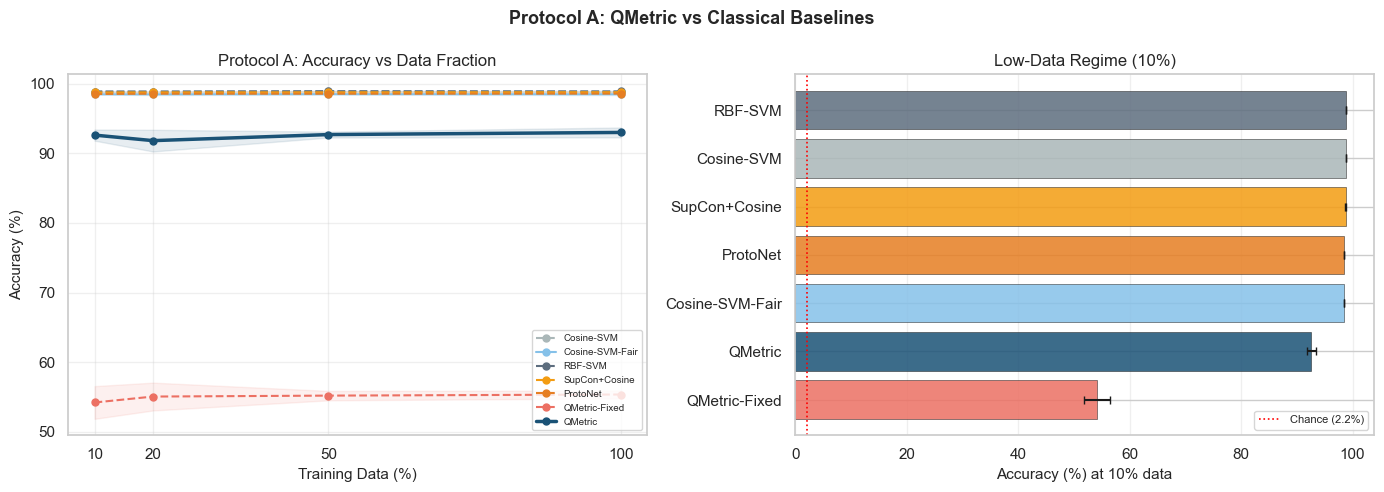

Protocol A plot saved to protocol_a_results.png


In [25]:
##################################################
# Protocol A — Results Table & Visualization
##################################################

agg_main = (proto_a_df
            .groupby(["fraction", "method"])["accuracy"]
            .agg(mean="mean", std="std")
            .reset_index())

print("\n" + "="*82)
print("PROTOCOL A — Mean Accuracy ± Std over seeds")
print("="*82)
print(f"{'Method':25s}", end="")
for f in DATA_FRACS:
    print(f"  {int(f*100):3d}%         ", end="")
print()
print("-"*82)
for method in agg_main["method"].unique():
    row = f"  {method:23s}"
    for frac in DATA_FRACS:
        sub = agg_main[(agg_main.method == method) & (agg_main.fraction == frac)]
        if len(sub) > 0:
            m, s = sub["mean"].values[0], sub["std"].values[0]
            cell = f"{m:.3f}±{s:.3f}" if (not np.isnan(s) and s > 0) else f"{m:.3f}     "
            row += f"  {cell}"
    print(row)
print("="*82)

# Plot: line chart + bar chart
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

order = ["Cosine-SVM", "Cosine-SVM-Fair", "RBF-SVM", "SupCon+Cosine",
         "LMNN+SVM", "ProtoNet", "QMetric-Fixed", "QMetric"]
for method in order:
    if method not in agg_main["method"].unique(): continue
    sub = agg_main[agg_main.method == method].sort_values("fraction")
    lw  = 2.5 if method == "QMetric" else 1.5
    ls  = "-" if method in ["QMetric", "Cosine-SVM-Fair"] else "--"
    axes[0].plot(sub.fraction * 100, sub["mean"] * 100,
                 color=METHOD_COLORS.get(method, "gray"),
                 lw=lw, marker="o", ms=5, ls=ls, label=method)
    axes[0].fill_between(sub.fraction * 100,
                         (sub["mean"] - sub["std"]) * 100,
                         (sub["mean"] + sub["std"]) * 100,
                         alpha=0.10, color=METHOD_COLORS.get(method, "gray"))
axes[0].set_xlabel("Training Data (%)", fontsize=11)
axes[0].set_ylabel("Accuracy (%)", fontsize=11)
axes[0].set_title("Protocol A: Accuracy vs Data Fraction", fontsize=12)
axes[0].legend(fontsize=7, loc="lower right")
axes[0].set_xticks([10, 20, 50, 100])
axes[0].grid(True, alpha=0.3)

# Low-data bar chart (10% data)
d10  = agg_main[agg_main.fraction == 0.10].sort_values("mean")
cols = [METHOD_COLORS.get(m, "gray") for m in d10.method]
axes[1].barh(d10.method, d10["mean"] * 100, xerr=d10["std"] * 100,
             capsize=3, color=cols, alpha=0.85, edgecolor="k", linewidth=0.4)
axes[1].set_xlabel("Accuracy (%) at 10% data", fontsize=11)
axes[1].set_title("Low-Data Regime (10%)", fontsize=12)
axes[1].grid(True, alpha=0.3, axis="x")
axes[1].axvline(100 / NUM_CLASSES, color="red", linestyle=":", lw=1.2,
                label=f"Chance ({100/NUM_CLASSES:.1f}%)")
axes[1].legend(fontsize=8)

plt.suptitle("Protocol A: QMetric vs Classical Baselines", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("protocol_a_results.png", dpi=150, bbox_inches="tight")
plt.show()
print("Protocol A plot saved to protocol_a_results.png")


## Section 6: Few-Shot Evaluation (Protocol B)

In [26]:
#############################################
# Episode sampler & QML Predictor
############################################

N_WAY  = 5

def sample_episode(embeddings, labels, n_way=N_WAY, k_shot=1, n_query=15, rng=None):
    """Sample a single N-way K-shot episode."""
    if rng is None: rng = np.random.default_rng(SEED)
    all_classes = np.unique(labels)
    episode_cls = rng.choice(all_classes, size=n_way, replace=False)
    cls_map     = {c: i for i, c in enumerate(episode_cls)}
    X_s, y_s, X_q, y_q = [], [], [], []
    for cls in episode_cls:
        cls_idx  = np.where(labels == cls)[0]
        n_needed = k_shot + n_query
        chosen   = rng.choice(cls_idx, size=n_needed,
                               replace=len(cls_idx) < n_needed)
        X_s.append(embeddings[chosen[:k_shot]])
        y_s.extend([cls_map[cls]] * k_shot)
        X_q.append(embeddings[chosen[k_shot:]])
        y_q.extend([cls_map[cls]] * n_query)
    return (np.vstack(X_s), np.array(y_s), np.vstack(X_q), np.array(y_q))

def make_qml_episode_predictor(trained_qml_layer):
    """Wrap a trained QML layer as an episode-level predictor."""
    def qml_episode(X_support, y_support, X_query):
        trained_qml_layer.eval()
        Xs_t = torch.FloatTensor(X_support).to(DEVICE)
        Xq_t = torch.FloatTensor(X_query).to(DEVICE)
        with torch.no_grad():
            K_ss = trained_qml_layer.kernel_matrix(Xs_t).cpu().numpy()
            K_qs = trained_qml_layer.cross_kernel(Xq_t, Xs_t).cpu().numpy()
        svm = SVC(kernel="precomputed", C=1.0)
        svm.fit(K_ss, y_support)
        return svm.predict(K_qs)
    return qml_episode

print("Few-shot utilities defined")

Few-shot utilities defined


In [27]:
#############################################
# 5-way K-shot Few-Shot Episodes
############################################

KSHOT_LIST   = [1, 5, 10]
N_EPISODES   = 200

print("Running Protocol B (5-way few-shot episodes)...")
proto_b_rows = []

for k in KSHOT_LIST:
    print(f"  K={k}-shot ({N_EPISODES} episodes)...")
    # Train a fresh QMetric for each k-shot configuration
    qml_t = QuantumMetricLayer().to(DEVICE)
    train_qml(qml_t, embeddings_train_full, lbl_train_full,
              n_epochs=60, verbose=False)
    qml_pred = make_qml_episode_predictor(qml_t)

    rng = np.random.default_rng(SEED)
    for ep in range(N_EPISODES):
        Xs, ys, Xq, yq = sample_episode(
            embeddings_train_full, lbl_train_full,
            n_way=N_WAY, k_shot=k, rng=rng
        )
        # ProtoNet
        yp_proto = prototypical_predict(Xs, ys, Xq)
        proto_b_rows.append({"k_shot": k, "episode": ep,
                              "method": "ProtoNet",
                              "accuracy": accuracy_score(yq, yp_proto)})
        # QMetric
        yp_qml = qml_pred(Xs, ys, Xq)
        proto_b_rows.append({"k_shot": k, "episode": ep,
                              "method": "QMetric",
                              "accuracy": accuracy_score(yq, yp_qml)})

proto_b_df = pd.DataFrame(proto_b_rows)
agg_b = (proto_b_df
         .groupby(["method", "k_shot"])["accuracy"]
         .agg(mean="mean", std="std")
         .reset_index())

print("\n PROTOCOL B RESULTS (mean ± std over episodes)")
print(f"{'Method':15s}", end="")
for k in KSHOT_LIST:
    print(f"  {k}-shot         ", end="")
print()
print("-"*60)
for method in agg_b.method.unique():
    row = f"  {method:13s}"
    for k in KSHOT_LIST:
        sub = agg_b[(agg_b.method == method) & (agg_b.k_shot == k)]
        if len(sub) > 0:
            row += f"  {sub['mean'].values[0]*100:.1f}±{sub['std'].values[0]*100:.1f}%  "
    print(row)

proto_b_df.to_csv("protocol_b_results.csv", index=False)
print("Protocol B complete — saved to protocol_b_results.csv")


Running Protocol B (5-way few-shot episodes)...
  K=1-shot (200 episodes)...
  K=5-shot (200 episodes)...
  K=10-shot (200 episodes)...

 PROTOCOL B RESULTS (mean ± std over episodes)
Method           1-shot           5-shot           10-shot         
------------------------------------------------------------
  ProtoNet       99.3±1.3%    99.9±0.4%    100.0±0.2%  
  QMetric        77.7±10.5%    90.2±5.5%    92.3±4.4%  
Protocol B complete — saved to protocol_b_results.csv


## Section 8: Confusion-Pair Stress Test (Protocol C)

In [28]:
#############################################
# Find hard pairs & Protocol C (Confusion-Pair Stress Test)
############################################

N_PAIRS      = 10

def find_hard_confusion_pairs(embeddings, labels, n_pairs=N_PAIRS):
    """Identify visually confusable character pairs by prototype cosine similarity."""
    classes = np.unique(labels)
    protos  = {}
    for c in classes:
        p = embeddings[labels == c].mean(0)
        protos[c] = p / (np.linalg.norm(p) + 1e-8)
    pairs = sorted(
        [(float(np.dot(protos[c1], protos[c2])), int(c1), int(c2))
         for c1, c2 in combinations(classes, 2)],
        key=lambda x: -x[0]
    )
    return [(c1, c2) for _, c1, c2 in pairs[:n_pairs]]

def evaluate_pair(X_all, y_all, pair, classifier_fn, test_size=0.3, seed=SEED):
    """Binary discrimination accuracy for a single confusion pair."""
    c1, c2 = pair
    mask   = (y_all == c1) | (y_all == c2)
    X_pair = X_all[mask]
    y_pair = (y_all[mask] == c1).astype(int)
    sss = StratifiedShuffleSplit(n_splits=1, test_size=test_size, random_state=seed)
    for tr_idx, te_idx in sss.split(X_pair, y_pair):
        Xtr, Xte = X_pair[tr_idx], X_pair[te_idx]
        ytr, yte = y_pair[tr_idx], y_pair[te_idx]
    return accuracy_score(yte, classifier_fn(Xtr, ytr, Xte))

def binary_cosine_svm(Xtr, ytr, Xte):
    """Binary classifier: cosine-kernel SVM."""
    def norm(X): return X / (np.linalg.norm(X, axis=1, keepdims=True) + 1e-8)
    svm = SVC(kernel="precomputed", C=1.0)
    svm.fit(norm(Xtr) @ norm(Xtr).T, ytr)
    return svm.predict(norm(Xte) @ norm(Xtr).T)

def binary_qml(qml_layer, Xtr, ytr, Xte):
    """
    Binary QMetric classifier for confusion-pair evaluation.
    QMetric comparison
    """
    qml_layer.eval()
    Xtr_t = torch.FloatTensor(Xtr).to(DEVICE)
    Xte_t = torch.FloatTensor(Xte).to(DEVICE)
    with torch.no_grad():
        K_tr = qml_layer.kernel_matrix(Xtr_t).cpu().numpy()
        K_te = qml_layer.cross_kernel(Xte_t, Xtr_t).cpu().numpy()
    svm = SVC(kernel="precomputed", C=1.0)
    svm.fit(K_tr, ytr)
    return svm.predict(K_te)

# Run Protocol C
hard_pairs = find_hard_confusion_pairs(embeddings_train_full, lbl_train_full)
print(f"Found {len(hard_pairs)} hard confusion pairs")

print("Training QMetric for Protocol C...")
qml_pair = QuantumMetricLayer().to(DEVICE)
train_qml(qml_pair, embeddings_train_full, lbl_train_full, n_epochs=60, verbose=False)

X_all = np.vstack([embeddings_train_full, embeddings_test])
y_all = np.concatenate([lbl_train_full, lbl_test])

proto_c_rows = []
for pair in hard_pairs:
    c1, c2    = pair
    pair_name = f"{CLASS_NAMES[c1]}↔{CLASS_NAMES[c2]}"

    # Cosine-SVM binary classifier
    acc_svm = evaluate_pair(X_all, y_all, pair, binary_cosine_svm)

    # QMetric binary classifier — NEW (was missing in original Protocol C)
    acc_qml = evaluate_pair(
        X_all, y_all, pair,
        lambda Xtr, ytr, Xte: binary_qml(qml_pair, Xtr, ytr, Xte)
    )

    proto_c_rows.append({
        "pair"        : pair_name,
        "SVM"         : acc_svm,
        "QMetric"     : acc_qml,
        "QMetric_gain": acc_qml - acc_svm,
    })
    print(f"  {pair_name:35s} | SVM={acc_svm:.3f} | QMetric={acc_qml:.3f} | "
          f"Gain={acc_qml-acc_svm:+.3f}")

proto_c_df = pd.DataFrame(proto_c_rows)
print("\n PROTOCOL C — Binary Disambiguation Results")
print(proto_c_df.to_string(index=False))
print(f"\nMean QMetric gain: {proto_c_df.QMetric_gain.mean()*100:+.2f}%")
print(f"QMetric wins     : {(proto_c_df.QMetric_gain > 0).sum()}/{len(proto_c_df)} pairs")
proto_c_df.to_csv("protocol_c_results.csv", index=False)
print("Protocol C complete — saved to protocol_c_results.csv")

Found 10 hard confusion pairs
Training QMetric for Protocol C...
  character_24_bha↔character_9_jha    | SVM=1.000 | QMetric=0.983 | Gain=-0.017
  character_13_daa↔character_5_kna    | SVM=0.997 | QMetric=0.978 | Gain=-0.019
  character_15_adna↔character_3_ga    | SVM=0.999 | QMetric=0.983 | Gain=-0.017
  character_30_motosaw↔character_36_gya | SVM=1.000 | QMetric=0.998 | Gain=-0.002
  digit_2↔digit_3                     | SVM=1.000 | QMetric=0.998 | Gain=-0.002
  character_13_daa↔character_14_dhaa  | SVM=1.000 | QMetric=0.995 | Gain=-0.005
  character_7_chha↔digit_6            | SVM=1.000 | QMetric=0.983 | Gain=-0.017
  character_16_tabala↔character_28_la | SVM=0.999 | QMetric=0.977 | Gain=-0.022
  character_2_kha↔character_32_patalosaw | SVM=1.000 | QMetric=0.993 | Gain=-0.007
  character_11_taamatar↔digit_8       | SVM=0.999 | QMetric=0.992 | Gain=-0.007

 PROTOCOL C — Binary Disambiguation Results
                                  pair      SVM  QMetric  QMetric_gain
      characte

## Section 9: Ablation Study (C3)

In [29]:
#############################################
# Ablation: GAL Component Contribution Study
############################################

ABLATION_VARIANTS = {
    "Full QMetric"            : dict(alpha=0.5, beta=0.4, gamma=0.1),
    "KTA only (no QSC)"       : dict(alpha=1.0, beta=0.0, gamma=0.1),
    "QSC only (no KTA)"       : dict(alpha=0.0, beta=1.0, gamma=0.1),
    "No L_var"                : dict(alpha=0.5, beta=0.4, gamma=0.0),
    "No GAL (random kernel)"  : None,
}

abl_rows = []
idx20 = balanced_class_subsample(lbl_train_full, int(len(lbl_train_full) * 0.20))
Xtr20, ytr20 = embeddings_train_full[idx20], lbl_train_full[idx20]

print(f"Running ablation (20% data, {N_SEEDS} seeds)...")
for variant, gal_kwargs in ABLATION_VARIANTS.items():
    accs = []
    for seed in range(N_SEEDS):
        set_seed(seed)
        qml_v = QuantumMetricLayer().to(DEVICE)
        if gal_kwargs is not None:
            train_qml(qml_v, Xtr20, ytr20,
                      n_epochs=80,
                      verbose=False, **gal_kwargs)
        acc, f1, _ = evaluate_qml(qml_v, Xtr20, ytr20, embeddings_test, lbl_test)
        accs.append(acc)
        abl_rows.append({"variant": variant, "seed": seed, "accuracy": acc})
    print(f"  {variant:35s}: {np.mean(accs):.4f} ± {np.std(accs):.4f}")

ablation_df = pd.DataFrame(abl_rows)
agg_abl = (ablation_df
           .groupby("variant")["accuracy"]
           .agg(mean="mean", std="std")
           .sort_values("mean", ascending=False))

print("\n ABLATION RESULTS")
print(agg_abl.to_string())

# Sanity check: Full QMetric must outperform No-GAL (else loss balance still broken)
try:
    full_qm = agg_abl.loc["Full QMetric", "mean"]
    no_gal  = agg_abl.loc["No GAL (random kernel)", "mean"]
    if full_qm > no_gal + 0.02:
        print(f"\n✅ C3 SUPPORTED: Full QMetric ({full_qm:.4f}) > No-GAL ({no_gal:.4f})")
    elif full_qm > no_gal:
        print(f"\n⚠️  C3 WEAK: Full QMetric ({full_qm:.4f}) > No-GAL ({no_gal:.4f}) but margin < 2pp")
    else:
        print(f"\n❌ C3 FAILED: Full QMetric ({full_qm:.4f}) ≤ No-GAL ({no_gal:.4f})")
        print("   Check: loss normalisation, QML_EPOCHS, LR values")
except: pass

ablation_df.to_csv("ablation_results.csv", index=False)
print("Ablation complete — saved to ablation_results.csv")


Running ablation (20% data, 3 seeds)...
  Full QMetric                       : 0.8230 ± 0.0018
  KTA only (no QSC)                  : 0.7975 ± 0.0179
  QSC only (no KTA)                  : 0.8125 ± 0.0192
  No L_var                           : 0.8234 ± 0.0010
  No GAL (random kernel)             : 0.5418 ± 0.0168

 ABLATION RESULTS
                            mean       std
variant                                   
No L_var                0.823406  0.001270
Full QMetric            0.823019  0.002180
QSC only (no KTA)       0.812512  0.023493
KTA only (no QSC)       0.797536  0.021947
No GAL (random kernel)  0.541787  0.020581

✅ C3 SUPPORTED: Full QMetric (0.8230) > No-GAL (0.5418)
Ablation complete — saved to ablation_results.csv


## Section 10: Statistical Analysis & Significance Testing

In [30]:
##################################################
# Paired t-tests + Cohen's d: QMetric vs Baselines
##################################################

print("\n" + "="*75)
print("STATISTICAL SIGNIFICANCE (paired t-test, alpha=0.05)")
print("="*75)

stat_rows = []

if "QMetric" in proto_a_df.method.unique():
    for frac in DATA_FRACS:
        fdf     = proto_a_df[proto_a_df.fraction == frac]
        qm_seed_accs = (fdf[fdf.method == "QMetric"]
                        .sort_values("seed")["accuracy"].values)
        if len(qm_seed_accs) < 2:
            print(f"\nFraction {frac:.0%}: need ≥2 seeds for t-test (got {len(qm_seed_accs)})")
            continue

        print(f"\nData fraction: {frac:.0%}  (N={len(qm_seed_accs)} seeds)")
        print(f"  {'Method':28s}  {'Delta':>8s}  {'p-value':>9s}  {'Sig':>4s}  {'Cohen d':>8s}")
        print(f"  {'-'*65}")

        for method in [m for m in fdf.method.unique() if m != "QMetric"]:
            bl_seed_accs = (fdf[fdf.method == method]
                            .sort_values("seed")["accuracy"].values)
            if len(bl_seed_accs) < 2: continue
            n = min(len(qm_seed_accs), len(bl_seed_accs))
            try:
                t_stat, p_val = ttest_rel(qm_seed_accs[:n], bl_seed_accs[:n])
                diff          = (qm_seed_accs[:n] - bl_seed_accs[:n]).mean()
                d_arr         = qm_seed_accs[:n] - bl_seed_accs[:n]
                cohens_d      = diff / (d_arr.std() + 1e-9)
                sig           = "✅" if p_val < 0.05 else "❌"
                print(f"  {'QMetric vs ' + method:28s}  {diff*100:+7.2f}%  {p_val:9.4f}  {sig:4s}  {cohens_d:+8.2f}")
                stat_rows.append({
                    "fraction": frac, "vs_method": method,
                    "delta_pct": diff * 100, "p_value": p_val,
                    "cohens_d": cohens_d,
                    "significant": p_val < 0.05
                })
            except Exception as e:
                print(f"  {method}: {e}")

print("\n(✅ = p<0.05 | Cohen d: |d|≥0.2 small, |d|≥0.5 medium, |d|≥0.8 large)")

stat_df = pd.DataFrame(stat_rows)
if len(stat_df) > 0:
    stat_df.to_csv("statistical_analysis.csv", index=False)
    print("Statistical analysis saved to statistical_analysis.csv")



STATISTICAL SIGNIFICANCE (paired t-test, alpha=0.05)

Data fraction: 10%  (N=3 seeds)
  Method                           Delta    p-value   Sig   Cohen d
  -----------------------------------------------------------------
  QMetric vs Cosine-SVM           -6.25%     0.0059  ✅        -9.15
  QMetric vs RBF-SVM              -6.25%     0.0057  ✅        -9.32
  QMetric vs SupCon+Cosine        -6.13%     0.0064  ✅        -8.78
  QMetric vs Cosine-SVM-Fair      -5.86%     0.0061  ✅        -8.98
  QMetric vs ProtoNet             -5.91%     0.0057  ✅        -9.32
  QMetric vs QMetric-Fixed       +38.40%     0.0014  ✅       +19.07

Data fraction: 20%  (N=3 seeds)
  Method                           Delta    p-value   Sig   Cohen d
  -----------------------------------------------------------------
  QMetric vs Cosine-SVM           -7.05%     0.0169  ✅        -5.37
  QMetric vs RBF-SVM              -7.04%     0.0163  ✅        -5.47
  QMetric vs SupCon+Cosine        -6.94%     0.0166  ✅        -5

Training sample QMetric at 20% data for curve visualisation...


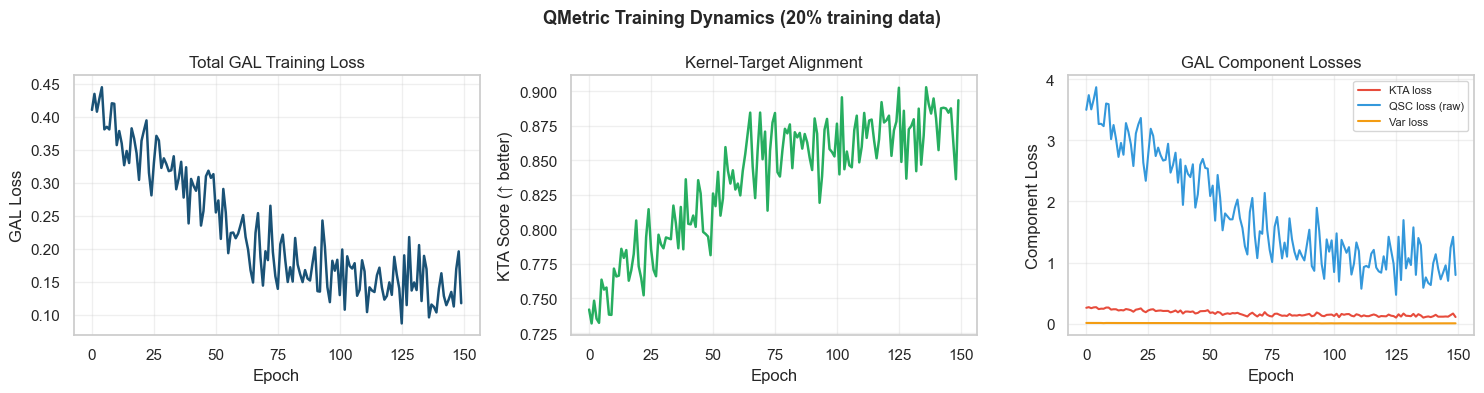

Training curves saved to training_curves.png


In [31]:
##################################################
# Training Loss Curves (QMetric @ 20% data)
##################################################

sample_frac = 0.20
print(f"Training sample QMetric at {sample_frac:.0%} data for curve visualisation...")

idx_s        = balanced_class_subsample(lbl_train_full, int(len(lbl_train_full) * sample_frac))
Xtr_s, ytr_s = embeddings_train_full[idx_s], lbl_train_full[idx_s]

qml_curve  = QuantumMetricLayer().to(DEVICE)
hist_curve = train_qml(qml_curve, Xtr_s, ytr_s, n_epochs=QML_EPOCHS, verbose=False)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(hist_curve["loss"], lw=1.8, color="#1a5276")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("GAL Loss")
axes[0].set_title("Total GAL Training Loss"); axes[0].grid(True, alpha=0.3)

axes[1].plot(hist_curve["kta_score"], lw=1.8, color="#27ae60")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("KTA Score (↑ better)")
axes[1].set_title("Kernel-Target Alignment"); axes[1].grid(True, alpha=0.3)

if len(hist_curve.get("qsc_loss", [])) > 0:
    axes[2].plot(hist_curve["kta_loss"], lw=1.5, color="#e74c3c", label="KTA loss")
    axes[2].plot(hist_curve["qsc_loss"], lw=1.5, color="#3498db", label="QSC loss (raw)")
    axes[2].plot(hist_curve["var_loss"], lw=1.5, color="#f39c12", label="Var loss")
    axes[2].set_xlabel("Epoch"); axes[2].set_ylabel("Component Loss")
    axes[2].set_title("GAL Component Losses"); axes[2].legend(fontsize=8)
    axes[2].grid(True, alpha=0.3)

plt.suptitle(f"QMetric Training Dynamics ({int(sample_frac*100)}% training data)",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("training_curves.png", dpi=150, bbox_inches="tight")
plt.show()
print("Training curves saved to training_curves.png")


## Section 11 — Comprehensive Analysis & Visualization

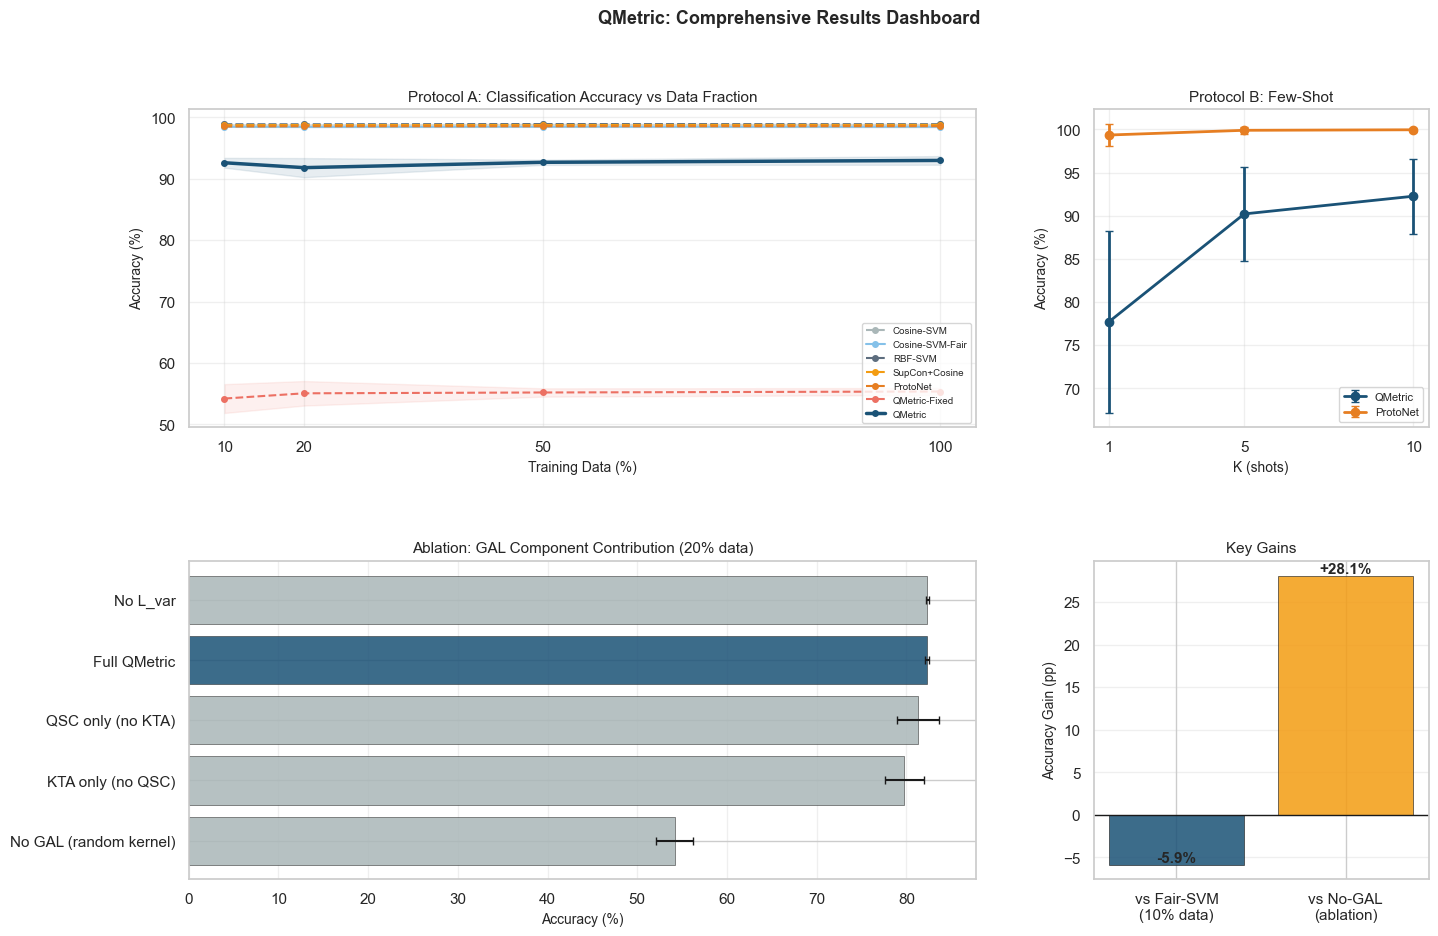

Dashboard saved to comprehensive_dashboard.png


In [32]:
##################################################
# Comprehensive Results Dashboard
##################################################

fig = plt.figure(figsize=(16, 10))
gs  = fig.add_gridspec(2, 3, hspace=0.42, wspace=0.35)

# Panel 1: Protocol A line chart
ax1 = fig.add_subplot(gs[0, :2])
order_main = ["Cosine-SVM","Cosine-SVM-Fair","RBF-SVM","LMNN+SVM",
              "SupCon+Cosine","ProtoNet","QMetric-Fixed","QMetric"]
for method in order_main:
    if method not in agg_main["method"].unique(): continue
    sub = agg_main[agg_main.method == method].sort_values("fraction")
    lw  = 2.5 if method == "QMetric" else 1.5
    ls  = "-" if method in ["QMetric","Cosine-SVM-Fair"] else "--"
    ax1.plot(sub.fraction * 100, sub["mean"] * 100,
             color=METHOD_COLORS.get(method,"gray"), lw=lw, marker="o", ms=4,
             ls=ls, label=method)
    ax1.fill_between(sub.fraction * 100,
                     (sub["mean"] - sub["std"]) * 100,
                     (sub["mean"] + sub["std"]) * 100,
                     alpha=0.10, color=METHOD_COLORS.get(method,"gray"))
ax1.set_xlabel("Training Data (%)", fontsize=10)
ax1.set_ylabel("Accuracy (%)", fontsize=10)
ax1.set_title("Protocol A: Classification Accuracy vs Data Fraction", fontsize=11)
ax1.legend(fontsize=7, loc="lower right")
ax1.set_xticks([10, 20, 50, 100]); ax1.grid(True, alpha=0.3)

# Panel 2: Protocol B
ax2 = fig.add_subplot(gs[0, 2])
for method in ["QMetric","ProtoNet"]:
    if method not in agg_b["method"].unique(): continue
    sub = agg_b[agg_b.method == method].sort_values("k_shot")
    ax2.errorbar(sub.k_shot, sub["mean"] * 100, yerr=sub["std"] * 100,
                 marker="o", lw=2, capsize=3, label=method,
                 color="#1a5276" if method == "QMetric" else "#e67e22")
ax2.set_xlabel("K (shots)", fontsize=10)
ax2.set_ylabel("Accuracy (%)", fontsize=10)
ax2.set_title("Protocol B: Few-Shot", fontsize=11)
ax2.legend(fontsize=8); ax2.set_xticks(KSHOT_LIST); ax2.grid(True, alpha=0.3)

# Panel 3: Ablation bar
ax3 = fig.add_subplot(gs[1, :2])
abl_sort = agg_abl.sort_values("mean", ascending=True)
cols     = ["#1a5276" if v == "Full QMetric" else "#aab7b8" for v in abl_sort.index]
ax3.barh(abl_sort.index, abl_sort["mean"] * 100,
         xerr=abl_sort["std"] * 100, capsize=3,
         color=cols, alpha=0.85, edgecolor="k", lw=0.4)
ax3.set_xlabel("Accuracy (%)", fontsize=10)
ax3.set_title("Ablation: GAL Component Contribution (20% data)", fontsize=11)
ax3.grid(True, alpha=0.3, axis="x")

# Panel 4: Key gains summary
ax4 = fig.add_subplot(gs[1, 2])
try:
    qm_10   = proto_a_df[(proto_a_df.method == "QMetric")    &
                          (proto_a_df.fraction == 0.10)]["accuracy"].mean()
    fair_10 = proto_a_df[(proto_a_df.method == "Cosine-SVM-Fair") &
                          (proto_a_df.fraction == 0.10)]["accuracy"].mean()
    pa_gain = (qm_10 - fair_10) * 100
except:
    pa_gain = 0.0

try:
    full_qm  = agg_abl.loc["Full QMetric", "mean"] if "Full QMetric" in agg_abl.index else 0
    no_gal   = agg_abl.loc["No GAL (random kernel)", "mean"] if "No GAL (random kernel)" in agg_abl.index else 0
    abl_gain = (full_qm - no_gal) * 100
except:
    abl_gain = 0.0

summary = {"vs Fair-SVM\n(10% data)": pa_gain, "vs No-GAL\n(ablation)": abl_gain}
ax4.bar(summary.keys(), summary.values(),
        color=["#1a5276","#f39c12"], alpha=0.85, edgecolor="k", lw=0.5)
ax4.set_ylabel("Accuracy Gain (pp)", fontsize=10)
ax4.set_title("Key Gains", fontsize=11)
ax4.axhline(0, color="k", lw=1)
ax4.grid(True, alpha=0.3, axis="y")
for i, (k, v) in enumerate(summary.items()):
    ax4.text(i, v + 0.3, f"{v:+.1f}%", ha="center", fontweight="bold", fontsize=11)

plt.suptitle("QMetric: Comprehensive Results Dashboard", fontsize=13, fontweight="bold")
plt.savefig("comprehensive_dashboard.png", dpi=150, bbox_inches="tight")
plt.show()
print("Dashboard saved to comprehensive_dashboard.png")


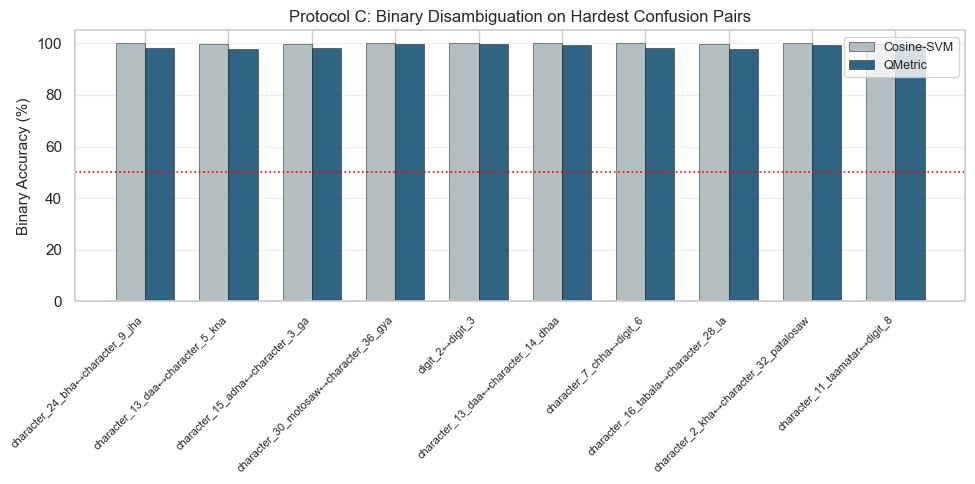

Protocol C plot saved to protocol_c_results.png


In [33]:
##################################################
# Protocol C Visualization
##################################################

if len(proto_c_df) > 0:
    fig, ax = plt.subplots(figsize=(10, 5))
    x = np.arange(len(proto_c_df))
    w = 0.35
    ax.bar(x - w/2, proto_c_df["SVM"] * 100,     width=w, label="Cosine-SVM",
           color="#aab7b8", edgecolor="k", lw=0.4, alpha=0.9)
    ax.bar(x + w/2, proto_c_df["QMetric"] * 100, width=w, label="QMetric",
           color="#1a5276", edgecolor="k", lw=0.4, alpha=0.9)
    ax.set_xticks(x)
    ax.set_xticklabels(proto_c_df["pair"], rotation=45, ha="right", fontsize=8)
    ax.set_ylabel("Binary Accuracy (%)", fontsize=11)
    ax.set_title("Protocol C: Binary Disambiguation on Hardest Confusion Pairs", fontsize=12)
    ax.legend(fontsize=9)
    ax.axhline(50, color="red", linestyle=":", lw=1.2, label="Chance (50%)")
    ax.grid(True, alpha=0.3, axis="y")
    plt.tight_layout()
    plt.savefig("protocol_c_results.png", dpi=150, bbox_inches="tight")
    plt.show()
    print("Protocol C plot saved to protocol_c_results.png")
